# Lab 2 — część B: Rasterio i NDVI (Opole)
**Andrii Zaluskyi, nr albumu 109585** · Analiza danych przestrzennych, Politechnika Opolska

Dane: Sentinel-2 L2A z **28 października 2026 r.**, pasma **B04 (Red, 665 nm)** i **B08 (NIR, 842 nm)**, pobrane z Copernicus Browser (TIFF 32-bit float, WGS 84). Prowadzący w przykładzie użył sceny z 6.10.2026 — dla tej daty i własnego zakresu obszaru wyniki liczbowe są inne, metoda jest ta sama.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

B04 = "dane/S2_L2A_2026-10-28_B04.tiff"   # Red
B08 = "dane/S2_L2A_2026-10-28_B08.tiff"   # NIR
OUT = Path("wyniki"); OUT.mkdir(exist_ok=True)
print("rasterio", rasterio.__version__, "| GDAL", rasterio.__gdal_version__)

rasterio 1.5.2 | GDAL 3.12.2


## B1. Raster i GeoTIFF
Raster to siatka pikseli (macierz liczb) + informacja, **gdzie na Ziemi ta siatka leży**: pasma, transformacja afiniczna, CRS i wartość nodata.

$$NDVI = \frac{NIR - Red}{NIR + Red} = \frac{B08 - B04}{B08 + B04} \in [-1, 1]$$

| NDVI | typowo |
|---|---|
| < 0 | woda |
| 0 – 0,2 | zabudowa, goła gleba |
| 0,2 – 0,5 | rzadka / słaba roślinność |
| > 0,5 | gęsta, zdrowa roślinność |

## B2. Otwarcie pliku i metadane

In [2]:
meta = {}
for name, path in [("B04 (Red)", B04), ("B08 (NIR)", B08)]:
    with rasterio.open(path) as src:          # samo otwarcie nie wczytuje pikseli
        meta[name] = {
            "driver": src.driver, "width": src.width, "height": src.height,
            "count": src.count, "dtype": src.dtypes[0], "crs": str(src.crs),
            "res": tuple(round(v, 8) for v in src.res), "nodata": src.nodata,
            "bounds": tuple(round(v, 6) for v in src.bounds),
        }
pd.DataFrame(meta)

,B04 (Red),B08 (NIR)
driver,GTiff,GTiff
width,2500,2500
height,2314,2314
count,1,1
dtype,float32,float32
crs,EPSG:4326,EPSG:4326
res,"(0.000109, 0.000069)","(0.000109, 0.000069)"
nodata,None,None
bounds,"(17.810226, 50.591084, 18.082809, 50.751011)","(17.810226, 50.591084, 18.082809, 50.751011)"


## B3. Piksel ↔ współrzędne

In [3]:
with rasterio.open(B04) as src:
    print(src.transform)
    row, col = src.height // 2, src.width // 2
    x, y = src.xy(row, col)                                  # (wiersz, kolumna) -> środek piksela
    print(f"piksel ({row}, {col}) -> x = {x:.6f}, y = {y:.6f}")
    print("z powrotem src.index(x, y):", src.index(x, y))
    red_px = float(src.read(1, window=((row, row + 1), (col, col + 1)))[0, 0])
    w_m = src.res[0] * 111320 * np.cos(np.radians(y))
    h_m = src.res[1] * 110540
with rasterio.open(B08) as src:
    nir_px = float(src.read(1, window=((row, row + 1), (col, col + 1)))[0, 0])

print(f"Red = {red_px:.4f}, NIR = {nir_px:.4f}, NDVI = {(nir_px - red_px) / (nir_px + red_px):.3f}")
print(f"Piksel {src.res[0]:.2e}° x {src.res[1]:.2e}° ≈ {w_m:.1f} m x {h_m:.1f} m — w stopniach piksel nie jest kwadratem")

| 0.00, 0.00, 17.81|
| 0.00,-0.00, 50.75|
| 0.00, 0.00, 1.00|
piksel (1157, 1250) -> x = 17.946572, y = 50.671013
z powrotem src.index(x, y): (1157, 1250)
Red = 0.0426, NIR = 0.2084, NDVI = 0.661
Piksel 1.09e-04° x 6.91e-05° ≈ 7.7 m x 7.6 m — w stopniach piksel nie jest kwadratem


## B4. Odczyt pasm i statystyki

In [4]:
bands = {}
for name, path in [("Red (B04)", B04), ("NIR (B08)", B08)]:
    with rasterio.open(path) as src:
        a = src.read(1, masked=True).astype("float32")      # nodata -> maska
        b = src.bounds
    bands[name] = (a, [b.left, b.right, b.bottom, b.top])

pd.DataFrame({n: {"min": a.min(), "max": a.max(), "średnia": a.mean(), "mediana": np.ma.median(a),
                  "odch. std.": a.std(), "piksele nodata": int(np.ma.count_masked(a))}
              for n, (a, _) in bands.items()}).T.astype(float).round(4)

,min,max,średnia,mediana,odch. std.,piksele nodata
Red (B04),0.0,1.4223,0.0588,0.0523,0.0384,0.0
NIR (B08),0.0,1.4473,0.2220,0.2095,0.0872,0.0


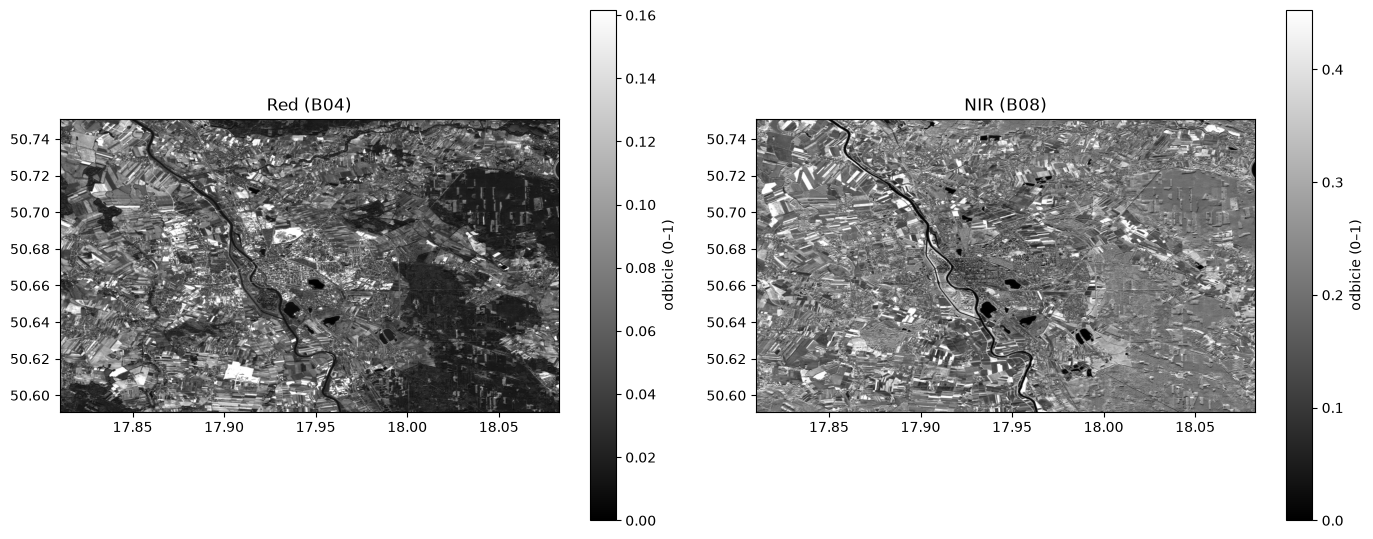

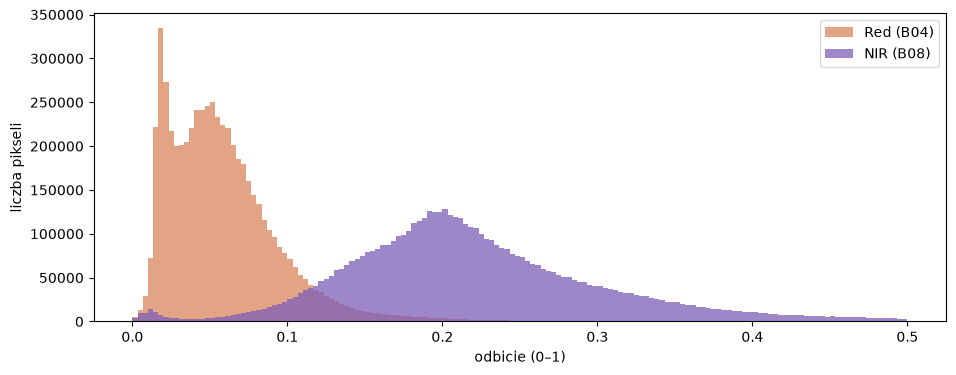

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, (a, ext)) in zip(axes, bands.items()):
    im = ax.imshow(a, cmap="gray", vmin=0, vmax=np.percentile(a.compressed(), 98), extent=ext)
    ax.set_title(name)
    fig.colorbar(im, ax=ax, label="odbicie (0–1)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
colors = {"Red (B04)": "#d9865c", "NIR (B08)": "#7e5fb8"}
for name, (a, _) in bands.items():
    ax.hist(a.compressed(), bins=150, range=(0, 0.5), alpha=0.75, label=name, color=colors[name])
ax.set_xlabel("odbicie (0–1)"); ax.set_ylabel("liczba pikseli"); ax.legend()
plt.show()

Woda jest ciemna w obu pasmach, a roślinność — ciemna w Red (B04) i jasna w NIR (B08). Na tej różnicy opiera się NDVI.

## B5. Wspólna siatka w metrach (EPSG:2180)

In [6]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

red_src, nir_src = rasterio.open(B04), rasterio.open(B08)
same_grid = (red_src.crs == nir_src.crs and red_src.transform == nir_src.transform
             and red_src.shape == nir_src.shape)
print("Pasma Red i NIR mają identyczną siatkę:", same_grid)

dst_crs = "EPSG:2180"
dst_transform, width, height = calculate_default_transform(
    red_src.crs, dst_crs, red_src.width, red_src.height, *red_src.bounds,
    resolution=10)                                         # Sentinel-2 B04/B08: natywnie 10 m

def warp(src):
    out = np.full((height, width), np.nan, dtype="float32")
    reproject(source=rasterio.band(src, 1), destination=out,
              dst_transform=dst_transform, dst_crs=dst_crs,
              dst_nodata=np.nan, resampling=Resampling.bilinear)
    return np.ma.masked_invalid(out)

red, nir = warp(red_src), warp(nir_src)
print(f"Przed: {red_src.crs}, {red_src.height} x {red_src.width} px, piksel {red_src.res[0]:.2e}°")
print(f"Do obliczeń: {dst_crs}, {height} x {width} px, piksel 10 x 10 m")
red_src.close(); nir_src.close()
extent_m = [dst_transform.c, dst_transform.c + width * dst_transform.a,
            dst_transform.f + height * dst_transform.e, dst_transform.f]

Pasma Red i NIR mają identyczną siatkę: True


Przed: EPSG:4326, 2314 x 2500 px, piksel 1.09e-04°
Do obliczeń: EPSG:2180, 1806 x 1952 px, piksel 10 x 10 m


## B6. Obliczenie NDVI

Średnie NDVI: 0.567   zakres: -0.83 … 1.00


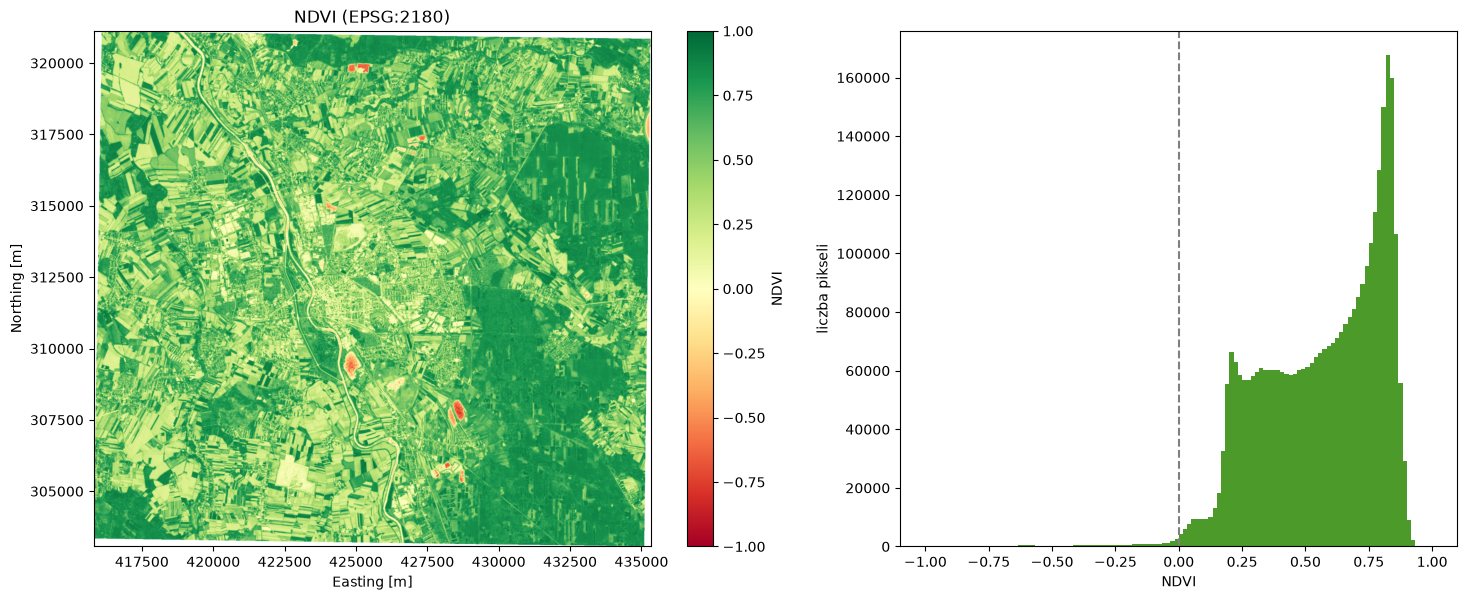

In [7]:
with np.errstate(divide="ignore", invalid="ignore"):      # 0 / 0 tam, gdzie oba pasma = 0
    ndvi = (nir - red) / (nir + red)
ndvi = np.ma.masked_invalid(ndvi)
print(f"Średnie NDVI: {ndvi.mean():.3f}   zakres: {ndvi.min():.2f} … {ndvi.max():.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax1.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1, extent=extent_m)
ax1.set_title("NDVI (EPSG:2180)"); ax1.set_xlabel("Easting [m]"); ax1.set_ylabel("Northing [m]")
fig.colorbar(im, ax=ax1, label="NDVI")
ax2.hist(ndvi.compressed(), bins=120, range=(-1, 1), color="#4c9a2a")
ax2.axvline(0, ls="--", color="gray"); ax2.set_xlabel("NDVI"); ax2.set_ylabel("liczba pikseli")
plt.tight_layout(); plt.show()

## B7. Klasyfikacja i powierzchnie

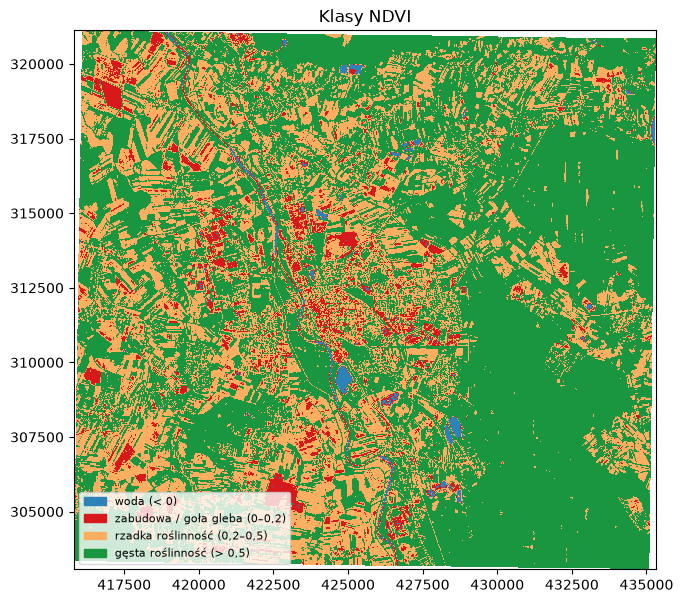

,klasa,piksele,powierzchnia [km²],udział [%]
0,woda (< 0),23946,2.39,0.7
1,"zabudowa / goła gleba (0–0,2)",184770,18.48,5.4
2,"rzadka roślinność (0,2–0,5)",1077399,107.74,31.5
3,"gęsta roślinność (> 0,5)",2137831,213.78,62.4


In [8]:
from matplotlib.colors import ListedColormap

bins = [-1.0, 0.0, 0.2, 0.5, 1.0001]
labels = ["woda (< 0)", "zabudowa / goła gleba (0–0,2)",
          "rzadka roślinność (0,2–0,5)", "gęsta roślinność (> 0,5)"]
counts = np.histogram(ndvi.compressed(), bins=bins)[0]
pix_km2 = abs(dst_transform.a * dst_transform.e) / 1e6
classes = pd.DataFrame({"klasa": labels, "piksele": counts,
                        "powierzchnia [km²]": (counts * pix_km2).round(2),
                        "udział [%]": (100 * counts / counts.sum()).round(1)})

cls = np.ma.masked_array(np.digitize(ndvi.filled(0), bins[1:-1]), mask=np.ma.getmaskarray(ndvi))
cmap = ListedColormap(["#2b83ba", "#d7191c", "#fdae61", "#1a9641"])
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cls, cmap=cmap, vmin=-0.5, vmax=3.5, extent=extent_m, interpolation="nearest")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in range(4)],
          labels=labels, loc="lower left", fontsize=8)
ax.set_title("Klasy NDVI"); plt.show()
classes

## B8. Statystyki strefowe (z GeoPandas)

In [9]:
from rasterio.features import geometry_mask

zones = gpd.read_file("dane/opole_districts.geojson").to_crs(dst_crs)   # ten sam CRS co raster!
ndvi_f = ndvi.filled(np.nan)
pixel_area = abs(dst_transform.a * dst_transform.e)

rows = []
for _, z in zones.iterrows():
    inside = geometry_mask([z.geometry], out_shape=ndvi_f.shape, transform=dst_transform, invert=True)
    vals = ndvi_f[inside]
    vals = vals[np.isfinite(vals)]
    rows.append({
        "name": z["name"],
        "pokrycie [%]": min(100, round(100 * vals.size * pixel_area / z.geometry.area)),  # część strefy w scenie
        "ndvi_mean": round(float(vals.mean()), 3) if vals.size else np.nan,
        "ndvi_min": round(float(vals.min()), 3) if vals.size else np.nan,
        "ndvi_max": round(float(vals.max()), 3) if vals.size else np.nan,
    })
stats = pd.DataFrame(rows).sort_values("ndvi_mean", ascending=False).reset_index(drop=True)
zones = zones.merge(stats, on="name")
stats

,name,pokrycie [%],ndvi_mean,ndvi_min,ndvi_max
0,Świerkle,27,0.758,-0.371,0.916
1,Grudzice,100,0.714,-0.067,0.951
2,Nadodrze,100,0.650,-0.176,0.917
3,Borki,100,0.582,0.090,0.883
4,Wrzoski,60,0.578,-0.026,0.932
5,Grotowice,89,0.542,-0.275,0.917
6,Chmielowice,100,0.538,-0.409,0.915
7,Bierkowice,100,0.536,0.001,0.931
8,Żerkowice,100,0.534,0.056,0.921
9,Krzanowice,100,0.529,-0.010,0.918


Dzielnice, które scena obejmuje tylko częściowo (pokrycie < 80%), mają średnią z fragmentu — do wniosków bierzemy tylko dzielnice z pokryciem ≥ 80%:

In [10]:
reliable = stats[stats["pokrycie [%]"] >= 80]
print("Najwyższe NDVI:"); print(reliable.head(3)[["name", "pokrycie [%]", "ndvi_mean"]].to_string(index=False))
print("\nNajniższe NDVI:"); print(reliable.tail(3)[["name", "pokrycie [%]", "ndvi_mean"]].to_string(index=False))

Najwyższe NDVI:
    name  pokrycie [%]  ndvi_mean
Grudzice           100      0.714
Nadodrze           100      0.650
   Borki           100      0.582

Najniższe NDVI:
        name  pokrycie [%]  ndvi_mean
     Zakrzów           100      0.392
 Śródmieście           100      0.381
Stare Miasto           100      0.353


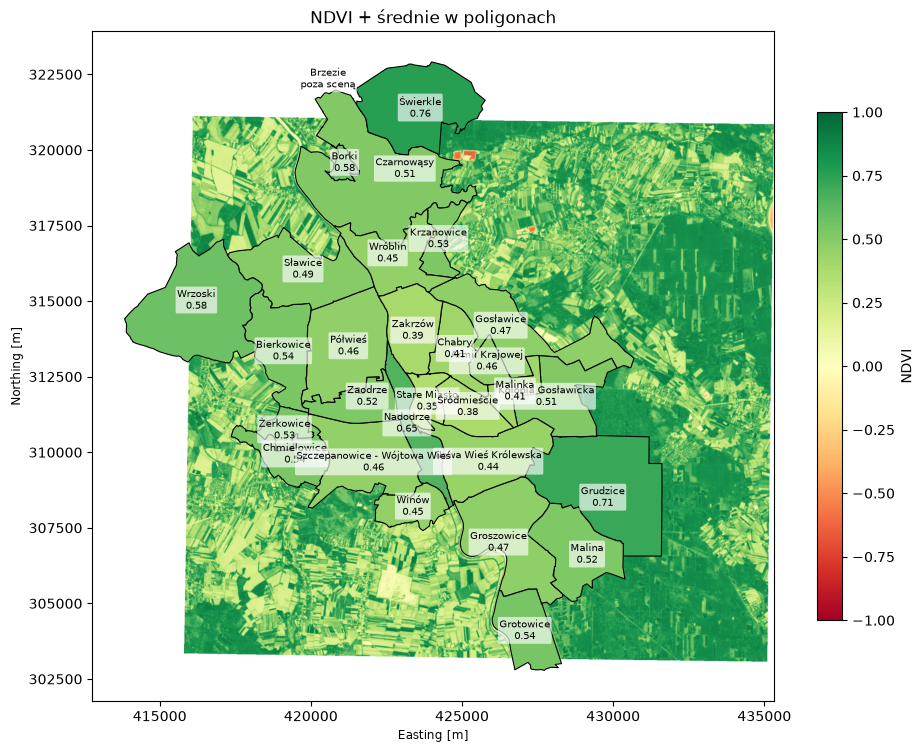

In [11]:
fig, ax = plt.subplots(figsize=(11, 11))
ax.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1, extent=extent_m)
zones.plot(ax=ax, column="ndvi_mean", cmap="RdYlGn", vmin=-1, vmax=1, edgecolor="black", linewidth=0.8)
for _, z in zones.iterrows():
    p = z.geometry.representative_point()
    label = f"{z['ndvi_mean']:.2f}" if pd.notna(z["ndvi_mean"]) else "poza sceną"
    ax.annotate(f"{z['name']}\n{label}", (p.x, p.y), ha="center", va="center", fontsize=7,
                bbox={"boxstyle": "round,pad=0.15", "fc": "white", "alpha": 0.65, "lw": 0})
sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(-1, 1))
fig.colorbar(sm, ax=ax, shrink=0.6, label="NDVI")
ax.set_title("NDVI + średnie w poligonach"); ax.set_xlabel("Easting [m]"); ax.set_ylabel("Northing [m]")
fig.savefig(OUT / "ndvi_dzielnice.png", dpi=150, bbox_inches="tight")
plt.show()

## B9. Zapis wyniku do GeoTIFF

In [12]:
profile = {"driver": "GTiff", "height": height, "width": width, "count": 1, "dtype": "float32",
           "crs": dst_crs, "transform": dst_transform, "nodata": np.nan, "compress": "deflate"}
tif = OUT / "ndvi_opole_2026-10-28.tif"
with rasterio.open(tif, "w", **profile) as dst:
    dst.write(ndvi.filled(np.nan).astype("float32"), 1)
stats.to_csv(OUT / "ndvi_dzielnice.csv", index=False)

with rasterio.open(tif) as chk:                           # kontrola zapisu
    print(tif, "|", chk.crs, "|", chk.width, "x", chk.height, "| piksel", chk.res)

wyniki/ndvi_opole_2026-10-28.tif | EPSG:2180 | 1952 x 1806 | piksel (10.0, 10.0)
